### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [1]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
    load_weather_nowcast,
    load_evaluation_forecast_data,
    load_scaler_params,
)
from training.plot import (
    plot_qr_hdi_prediction_ensemble,
    plot_bnn_gamma_combined,
    plot_qr_hdi_prediction_ensemble_combined,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
from training.evaluate import test_QR, test_BNN, crps_from_quantiles_torch
import torch
import re

from configs.load_config import load_config
from models.build import build_model
from data_processing.utils import load_checkpoint, extract_test_dates

In [2]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_bnn_gamma_combined

### Load evaluation data


In [3]:
representative_test_set = False

In [4]:
model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted_150.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3"

In [5]:
from types import SimpleNamespace

data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [6]:
bid_zone = model_cfg.data.bid_zone
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

# Scale nowcast and forecast with same scalers
scaler_data_nowcast = load_scaler_params(
    bid_zone=bid_zone, dataset="nowcast", dir_path="../checkpoints"
)

dataset = "forecast"  # data_cfg.dataset
if dataset == "nowcast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        # "2025-10-01",
        # "2025-10-02",
        # "2025-10-03",
    ]

    eval_data = load_evaluation_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
    )

elif dataset == "forecast":
    evaluation_dates = (
        [
            "2025-09-22",
            "2025-09-23",
            "2025-09-24",
            "2025-09-25",
            "2025-09-26",
            "2025-09-29",
            "2025-09-30",
            "2025-10-01",
            "2025-10-02",
            "2025-10-03",
        ]
        if not representative_test_set
        else extract_test_dates()
    )

    eval_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
        ensemble_members=None,
        variance_feature=False,
    )

Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-03-20 10:19:42
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO3...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-25 i

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 24, 15, 10)
Dropped timestamps due to maintenance: 0


In [7]:
# assert np.allclose(eval_data["X_eval"], eval_data_eff["X_eval"])

### Evaluate on test set


In [8]:
forecasts_ext = []
for member in range(15):

    if model_cfg.backend == "numpyro":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_BNN(
            file_name, eval_data, member=member
        )

    elif model_cfg.backend == "torch":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_QR(
            file_name,
            eval_data,
            ensembles=False,
            from_now_to_forecast=True,
            member=member,
        )
        checkpoint = torch.load(
            os.path.join("../checkpoints", f"{file_name}.pt"),
            map_location="cpu",
            weights_only=False,
        )

    forecasts_ext.append(forecast_extended[int(bz_from_checkpoint[-1]) - 1])

    if dataset == "nowcast":
        print("We use nowcast, so only one iteration")
        break

Choose ensemble member 0
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 1
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 2
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 3
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 4
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 5
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 6
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
Choose ensemble member 7
Loading specifie

In [9]:
df_out = pd.concat(forecasts_ext, axis=1, keys=range(len(forecasts_ext)))

df_out.columns = [f"{col}_{i}" for i, col in df_out.columns]

median_cols = df_out.filter(regex=r"^median_").columns
hdi_lower_cols = df_out.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = df_out.filter(regex=r"^hdi_upper_").columns

df_out["mean_median"] = df_out[median_cols].mean(axis=1)
df_out["std_median"] = df_out[median_cols].std(axis=1)
df_out["mean_hdi_lower"] = df_out[hdi_lower_cols].mean(axis=1)
df_out["std_hdi_lower"] = df_out[hdi_lower_cols].std(axis=1)
df_out["mean_hdi_upper"] = df_out[hdi_upper_cols].mean(axis=1)
df_out["std_hdi_upper"] = df_out[hdi_upper_cols].std(axis=1)

In [10]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [11]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [12]:
bid_zone = model_cfg.data.bid_zone.replace(" ", "_")
i = int(bid_zone.split("NO")[-1]) - 1
print(i, bid_zone)

rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

import properscoring as ps

if model_cfg.backend == "numpyro":
    crps = ps.crps_ensemble(eval_data["Y_eval_gen"], preds, axis=0).mean()
else:
    if checkpoint["model_cfg"].params.quantiles is None:
        quantiles = torch.linspace(0, 1, 51)
    else:
        quantiles = torch.tensor(checkpoint["model_cfg"].params.quantiles)
    print(eval_data["Y_eval_gen"].shape, preds.shape, quantiles.shape)
    crps = crps_from_quantiles_torch(
        eval_data["Y_eval_gen"],
        preds,
        quantiles,
    )
print("\nTest CRPS (gen prediction)", round(crps, 4))

2 ELSPOT_NO3
Test RMSE (gen prediction): 392.49182

Empirical coverage (0.025–0.975): 0.646
Below median (should be ~0.5): 0.525

Test CRPS (gen prediction) 228.4695


### Plot prediction


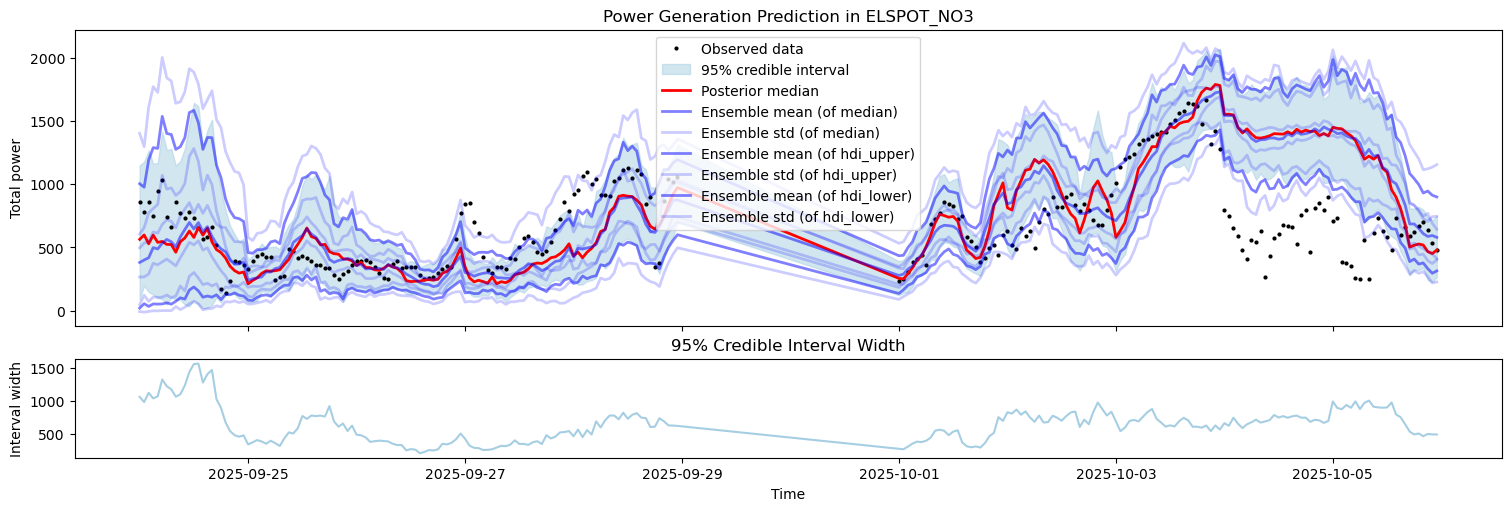

In [13]:
fig, axes = plt.subplots(
    nrows=2,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax = axes[0]
ax.plot(
    eval_data["index"],
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    # np.arange(len(df_out.index)),
    eval_data["index"],
    df_out["hdi_lower_0"].values,
    df_out["hdi_upper_0"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    eval_data["index"],
    df_out["median_0"].values,
    color="red",
    label="Posterior median",
    lw=2,
)

ax.set(
    ylabel="Total power",
    title=f"Power Generation Prediction in {bid_zone}",
)


# Compute interval width
width = df_out["hdi_upper_0"].values - df_out["hdi_lower_0"].values
ax2 = axes[1]
ax2.plot(eval_data["index"], width, color="#A6CEE3")
ax2.set(
    xlabel="Time",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

keys = ["median", "hdi_upper", "hdi_lower"]
colors = ["blue", "blue", "blue"]

for c, k in zip(colors, keys):
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values,
        color=c,
        lw=2,
        alpha=0.5,
        linestyle="-",
        label=f"Ensemble mean (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values + df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        # label=f"Ensemble std (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values - df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        label=f"Ensemble std (of {k})",
    )
ax.legend()

plt.show()

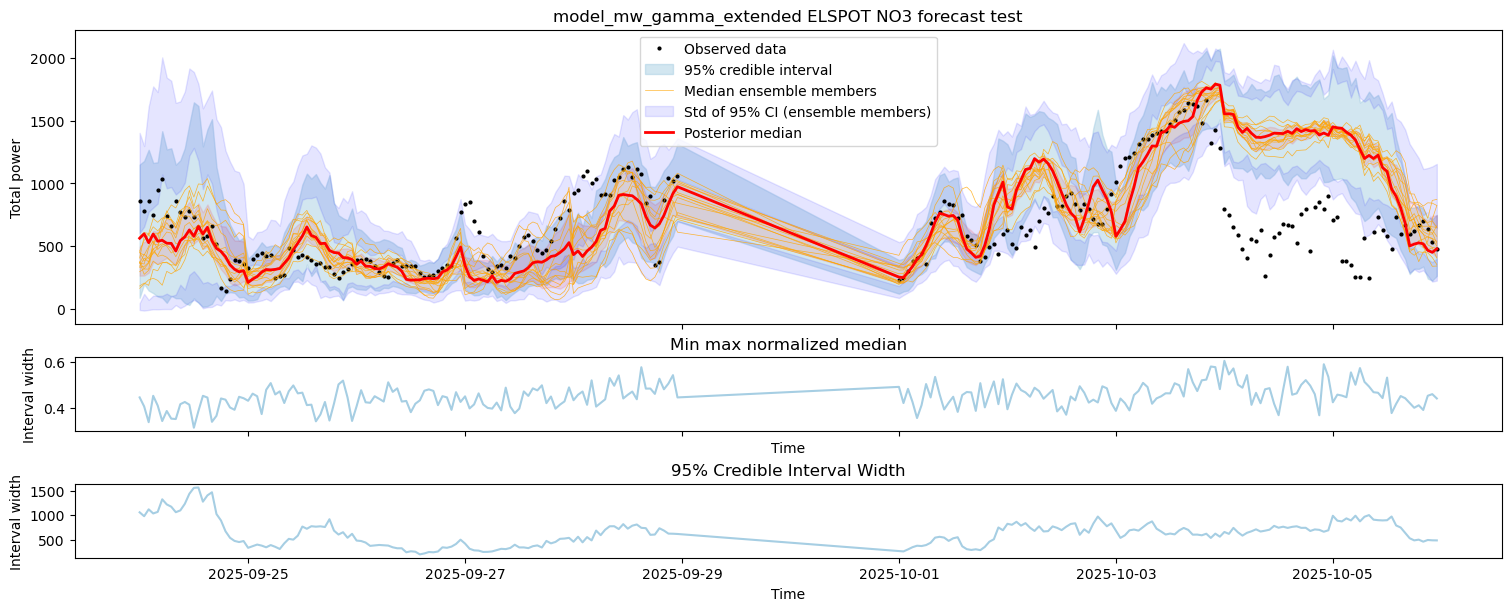

In [14]:
fix, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=eval_data["Y_eval_gen"],
    ensemble_results=df_out,
    n_plot=240,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} test",
    timestamps=eval_data["index"],
)

In [15]:
[col for col in df_out.columns if "hdi_lower" in col]

['hdi_lower_0',
 'hdi_lower_1',
 'hdi_lower_2',
 'hdi_lower_3',
 'hdi_lower_4',
 'hdi_lower_5',
 'hdi_lower_6',
 'hdi_lower_7',
 'hdi_lower_8',
 'hdi_lower_9',
 'hdi_lower_10',
 'hdi_lower_11',
 'hdi_lower_12',
 'hdi_lower_13',
 'hdi_lower_14',
 'mean_hdi_lower',
 'std_hdi_lower']

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl


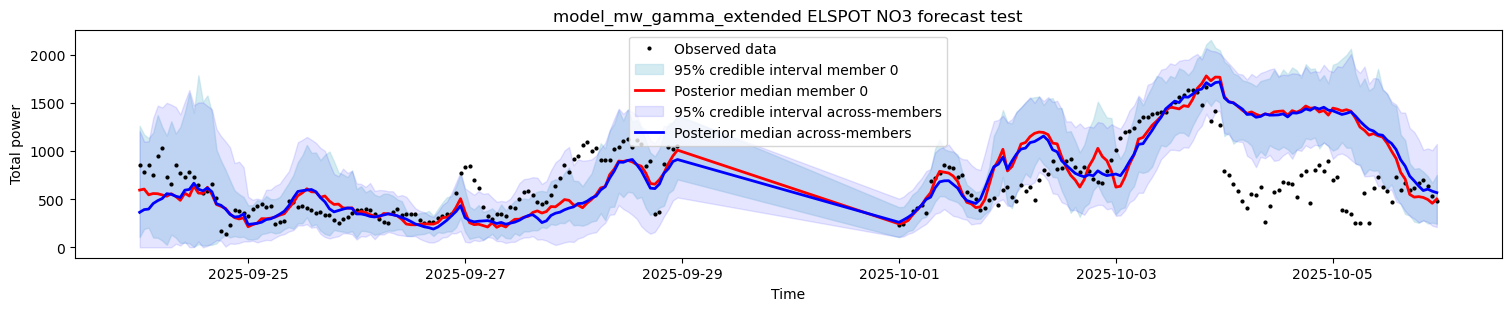

In [16]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], eval_data)

    plot_bnn_gamma_combined(checkpoint, model, eval_data, data_cfg, 240, "eval")
    plt.show()

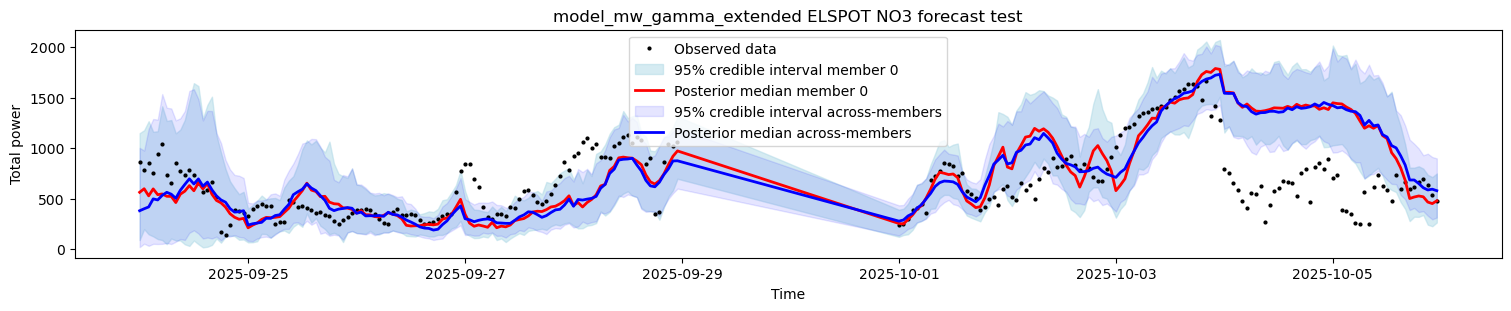

In [17]:
_, _ = plot_qr_hdi_prediction_ensemble_combined(
    Y_true=eval_data["Y_eval_gen"],
    conf_interval=[
        np.stack(
            [df_out["mean_hdi_lower"].values, df_out["mean_hdi_upper"].values], axis=-1
        ),
        np.stack([df_out["hdi_lower_0"].values, df_out["hdi_upper_0"].values], axis=-1),
    ],
    medians=[df_out["mean_median"].values, df_out["median_0"].values],
    n_plot=249,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} test",
    timestamps=df_out.index,
)

In [18]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [19]:
# # Now load forecast data using the SAME scaler parameters

# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=None,
#     site_scaler_params=None,
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )

In [20]:
# # Plot cf vs gen model for QR
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"QR Power Generation Prediction in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"QR Capacity Factor Prediction in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()

In [21]:
# # Plot cf vs gen model for BNN
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()